In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("creditcard.csv")

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


the dataset contains
1. time: time since the first transaction (in seconds)
2. v1 to v28: patterns
3. amount
4. class: 0=normal, 1=fraud

In [4]:
from sklearn.model_selection import train_test_split

In [6]:
#seperating features (x=input, y=output predicted)
#using 70% for training and 30% for testing
x = df.drop("Class", axis=1) #copy table without label

In [7]:
y = df['Class'] #only class column

In [10]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3) #splitting data

In [11]:
from sklearn.tree import DecisionTreeClassifier

In [12]:
clf = DecisionTreeClassifier()

In [14]:
clf.fit(x_train, y_train) #trained model

DecisionTreeClassifier()

In [15]:
y_pred = clf.predict(x_test)

In [18]:
from sklearn.metrics import accuracy_score

In [19]:
accuracy = accuracy_score(y_test, y_pred)

In [20]:
accuracy

0.9990871107053826

In [21]:
from sklearn.metrics import confusion_matrix

In [22]:
confusion_matrix(y_test, y_pred)

array([[85240,    44],
       [   34,   125]])

visualization of confusion matrix and data

In [23]:
import seaborn as sns

Text(0.5, 1.0, 'Confusion Matrix')

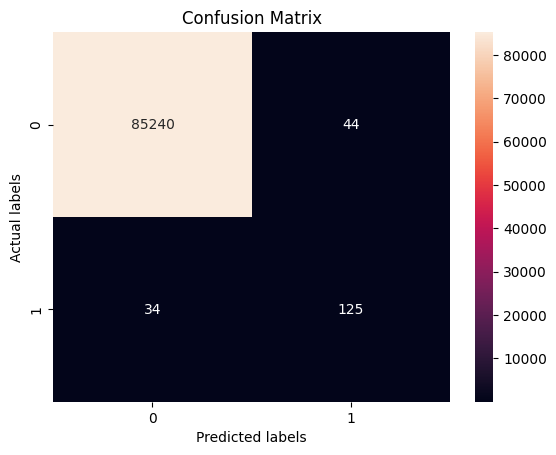

In [29]:
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d") #format=d is for int display
plt.xlabel('Predicted labels')
plt.ylabel('Actual labels')
plt.title('Confusion Matrix')

(array([2.84395e+05, 3.60000e+02, 3.60000e+01, 1.00000e+01, 2.00000e+00,
        1.00000e+00, 0.00000e+00, 2.00000e+00, 0.00000e+00, 1.00000e+00]),
 array([    0.   ,  2569.116,  5138.232,  7707.348, 10276.464, 12845.58 ,
        15414.696, 17983.812, 20552.928, 23122.044, 25691.16 ]),
 <BarContainer object of 10 artists>)

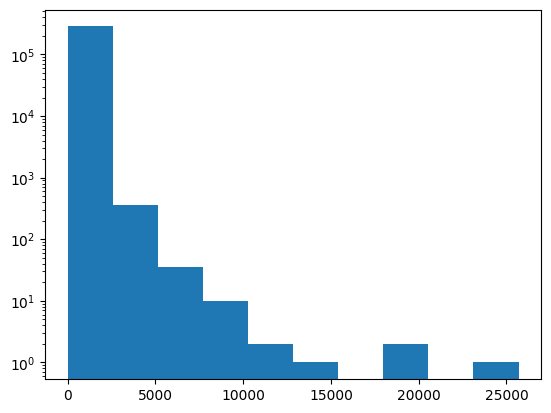

In [36]:
plt.yscale('log')
plt.hist(df['Amount'])